In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

folder = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"

print("Borde Soacha files:")
for name in sorted(os.listdir(folder)):
    path = os.path.join(folder, name)
    if os.path.isfile(path):
        print(f"{name}: {os.path.getsize(path) / (1024**3):.3f} GiB")

print("\nAerial TIFF exists:",
      os.path.isfile(os.path.join(folder, "borde_soacha_ortho-cog.tif")))

print("Training labels exist:",
      os.path.isfile(os.path.join(folder, "train-borde_soacha.geojson")))

print("Testing labels exist:",
      os.path.isfile(os.path.join(folder, "test-borde_soacha.geojson")))

print("Borde Rural still exists:",
      os.path.isdir("/content/drive/MyDrive/RoofMaterialProject/borde_rural"))


Borde Soacha files:
borde_soacha-imagery.json: 0.015 GiB
borde_soacha-labels-test.json: 0.000 GiB
borde_soacha-labels-train.json: 0.000 GiB
borde_soacha_ortho-cog-thumbnail.png: 0.001 GiB
borde_soacha_ortho-cog.tif: 4.236 GiB
collection.json: 0.000 GiB
test-borde_soacha.geojson: 0.002 GiB
train-borde_soacha.geojson: 0.004 GiB

Aerial TIFF exists: True
Training labels exist: True
Testing labels exist: True
Borde Rural still exists: True


In [ ]:

import os
import rasterio
import geopandas as gpd
from shapely.geometry import box

folder = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"
image_path = os.path.join(folder, "borde_soacha_ortho-cog.tif")
train_path = os.path.join(folder, "train-borde_soacha.geojson")
test_path = os.path.join(folder, "test-borde_soacha.geojson")

# 1. Inspect aerial image metadata
with rasterio.open(image_path) as src:
    image_crs = src.crs
    image_bounds = src.bounds
    image_footprint = box(*image_bounds)

    print("=== AERIAL IMAGE ===")
    print("CRS:", image_crs)
    print("Dimensions (width x height):", src.width, "x", src.height)
    print("Band count:", src.count)
    print("Data type:", src.dtypes)
    print("Pixel resolution:", src.res)
    print("Bounds:", image_bounds)
    print("Coordinate units:", src.crs.linear_units
          if src.crs and src.crs.is_projected else "Geographic or unknown")

# 2. Inspect training and testing labels
for label_path, label_name in [
    (train_path, "TRAIN"),
    (test_path, "TEST")
]:
    gdf = gpd.read_file(label_path)

    print(f"\n=== {label_name} LABELS ===")
    print("Rows:", len(gdf))
    print("CRS:", gdf.crs)
    print("Columns:", list(gdf.columns))
    print("Geometry types:", gdf.geometry.geom_type.value_counts().to_dict())

    if "roof_material" in gdf.columns:
        print("Roof-material counts:")
        print(gdf["roof_material"].value_counts(dropna=False).to_string())

    # Compare polygons against the image footprint in the image CRS
    if gdf.crs is not None:
        projected = gdf.to_crs(image_crs)
        valid = projected.geometry.notna() & ~projected.geometry.is_empty
        overlap = valid & projected.geometry.intersects(image_footprint)

        print("Valid, non-empty geometries:", int(valid.sum()))
        print("Polygons intersecting image footprint:", int(overlap.sum()))
        print("Polygons outside image footprint:", int((valid & ~overlap).sum()))
    else:
        print("WARNING: Label CRS is missing; overlap check skipped.")

    print("First 5 rows:")
    print(gdf.head().to_string(index=False))


=== AERIAL IMAGE ===
CRS: EPSG:32618
Dimensions (width x height): 45650 x 40159
Band count: 4
Data type: ('uint8', 'uint8', 'uint8', 'uint8')
Pixel resolution: (0.04258000000000001, 0.04258000000000001)
Bounds: BoundingBox(left=591256.29749, bottom=504126.94161000004, right=593200.07449, top=505836.91183000006)
Coordinate units: metre

=== TRAIN LABELS ===
Rows: 5995
CRS: EPSG:4326
Columns: ['id', 'roof_material', 'verified', 'geometry']
Geometry types: {'Polygon': 5987, 'MultiPolygon': 8}
Roof-material counts:
roof_material
healthy_metal      3161
irregular_metal    2124
incomplete          415
concrete_cement     280
other                15
Valid, non-empty geometries: 5995
Polygons intersecting image footprint: 5995
Polygons outside image footprint: 0
First 5 rows:
      id roof_material  verified                                                                                                  geometry
7a407f5a healthy_metal      True  POLYGON ((-74.17071 4.57317, -74.1706 4.57315, -

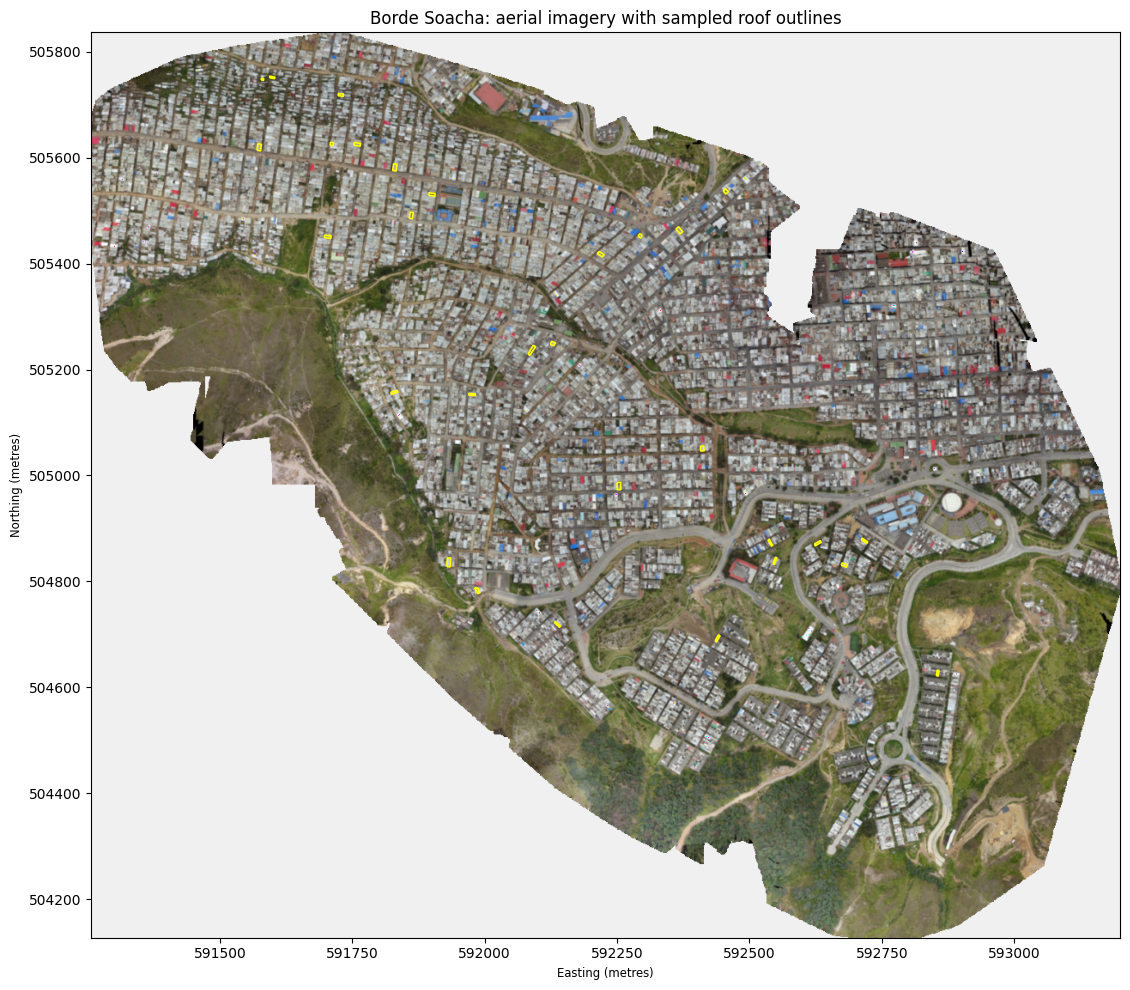

In [ ]:

import os
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

folder = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"
image_path = os.path.join(folder, "borde_soacha_ortho-cog.tif")
train_path = os.path.join(folder, "train-borde_soacha.geojson")

labels = gpd.read_file(train_path)

with rasterio.open(image_path) as src:
    # Read a small overview instead of the full 4.2 GB image.
    scale = min(1200 / src.width, 1200 / src.height)
    out_width = max(1, int(src.width * scale))
    out_height = max(1, int(src.height * scale))

    rgb = src.read(
        [1, 2, 3],
        out_shape=(3, out_height, out_width),
        resampling=Resampling.average
    )
    bounds = src.bounds
    image_crs = src.crs

labels_projected = labels.to_crs(image_crs)

sample = labels_projected.sample(
    n=min(30, len(labels_projected)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(12, 10))

ax.imshow(
    np.moveaxis(rgb, 0, -1),
    extent=[bounds.left, bounds.right, bounds.bottom, bounds.top],
    origin="upper"
)

sample.boundary.plot(ax=ax, color="yellow", linewidth=1.2)

ax.set_title("Borde Soacha: aerial imagery with sampled roof outlines")
ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")
plt.tight_layout()
plt.show()


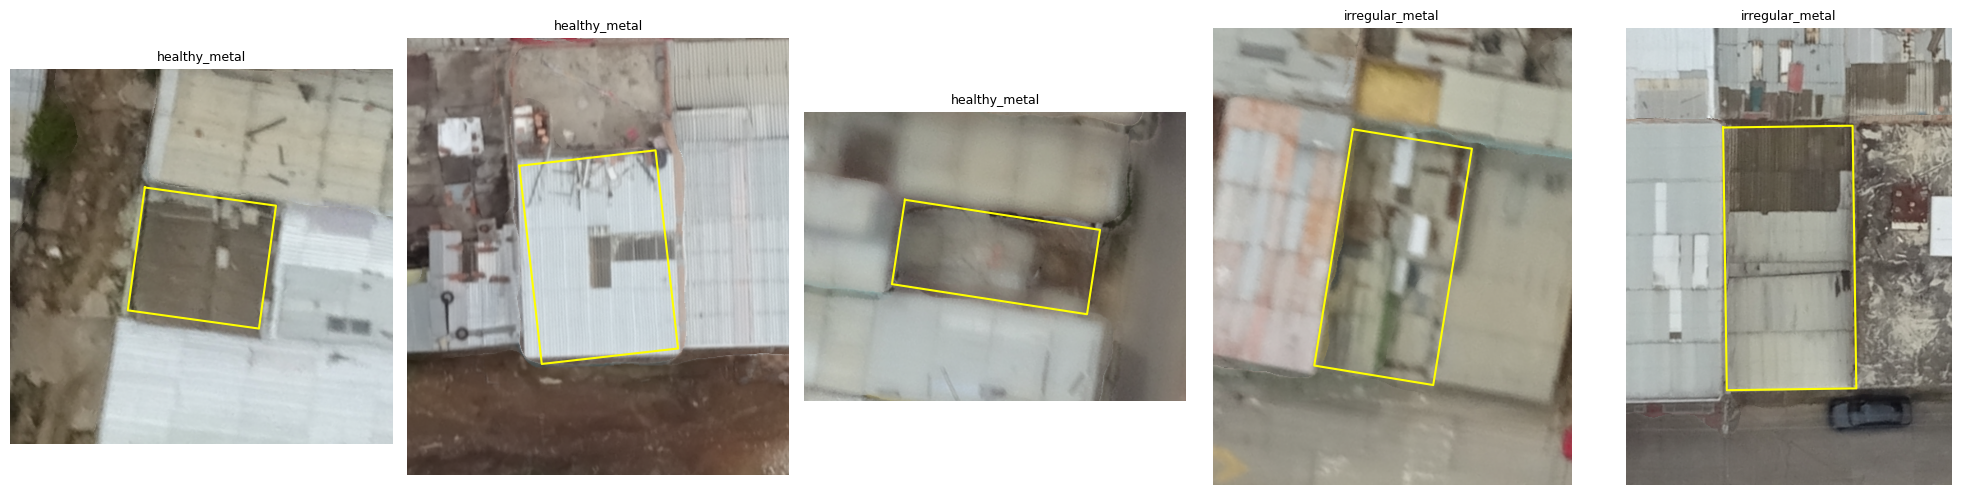

In [ ]:

import os
import random
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.windows import from_bounds

folder = "/content/drive/MyDrive/RoofMaterialProject/borde_soacha"
image_path = os.path.join(folder, "borde_soacha_ortho-cog.tif")
labels = gpd.read_file(os.path.join(folder, "train-borde_soacha.geojson"))

with rasterio.open(image_path) as src:
    labels = labels.to_crs(src.crs)
    sample = labels.sample(n=5, random_state=42)

    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, (_, row) in zip(axes, sample.iterrows()):
        geom = row.geometry
        minx, miny, maxx, maxy = geom.bounds

        # Add 5 metres of context around each building.
        window = from_bounds(
            minx - 5, miny - 5, maxx + 5, maxy + 5,
            transform=src.transform
        )
        window = window.round_offsets().round_lengths()
        image = src.read([1, 2, 3], window=window)

        ax.imshow(image.transpose(1, 2, 0))
        x0, y0 = ax.get_xlim()[0], ax.get_ylim()[1]

        # Plot the roof boundary relative to this image window.
        from rasterio.transform import xy
        from shapely.geometry import Polygon, MultiPolygon

        transform = src.window_transform(window)

        def pixel_coords(poly):
            coords = []
            for x, y in poly.exterior.coords:
                col, row_px = ~transform * (x, y)
                coords.append((col, row_px))
            return coords

        geoms = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]

        for part in geoms:
            coords = pixel_coords(part)
            ax.plot(
                [p[0] for p in coords],
                [p[1] for p in coords],
                color="yellow",
                linewidth=1.5
            )

        ax.set_title(str(row["roof_material"]), fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
